In [1]:
# Notebook 5: can frontier models do our job, and can our model run on the phones people actually have?
#   Part A - frontier agents (Claude, Gemini via their CLIs) vs our offline models on the same test photos
#   Part B - where and why the models err (distance to training data, region, built-in image-only head, occlusion)
#   Part C - on-device footprint (params, FLOPs, memory, latency, fp16) and the phone-market budget
#   Part D - every figure used by report/final_report.tex
# Inputs : outputs/notebook4/ (predictions + checkpoints written by notebook 4), datasets/
# Outputs: results/ (tracked CSVs, incl. every frontier answer), report/figures/final_*.png
import calendar
import json
import shutil
import statistics
import subprocess
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from PIL import Image
from torch.utils.data import DataLoader

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from evaluate import compute_test_distance_mask
from scripts.analysis.compare_final_models import paired_station_bootstrap_mae_diff
from scripts.final_evaluation import station_bootstrap_mae_ci
from src.config import load_config
from src.data.cleaning import EPA_BIN_LABELS, aqi_to_bin_index, load_and_clean_metadata
from src.data.dataset import PM25Dataset
from src.data.transforms import get_eval_transforms, unnormalize_image
from src.metrics import compute_all_metrics
from src.models.baselines import MetadataMLP
from train import build_image_model

SEED = 42
NB4 = PROJECT_ROOT / 'outputs' / 'notebook4'
FRONTIER = PROJECT_ROOT / 'results' / 'frontier'
FIG = PROJECT_ROOT / 'report' / 'figures'
FRONTIER.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')

BLUE, ORANGE, AQUA, VIOLET, GRAY, INK, INK2 = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6', '#898781', '#0b0b0b', '#52514e'
LIGHT_BLUE, LIGHT_GRAY, LIGHT_ORANGE, PALE = '#e8f1fc', '#f0efec', '#fdeee7', '#c3c2b7'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'savefig.dpi': 300, 'figure.dpi': 110})

# cleaned splits exactly as in notebook 4, plus distance to the nearest training photo and world region
train_df, test_df = load_and_clean_metadata('datasets/train/metadata.csv', 'datasets/test/metadata.csv')
test_df = test_df.reset_index(drop=True)
test_df['nearest_km'], test_df['gt25km'] = compute_test_distance_mask(train_df, test_df, min_km=25.0)
test_df['month'] = pd.to_datetime(test_df['captured_at']).dt.month
test_df = test_df.merge(pd.read_csv('features/clean_metadata.csv', usecols=['image_id', 'region']), on='image_id', how='left')

# every model's test predictions from notebook 4 (seed 42), one column per model
ALL_MODELS = ['Fusion R1', 'Metadata MLP', 'MobileNetV3-S', 'PFRML full', 'Fusion R1 (metadata off)', 'ResSE', 'HazeCNN',
              'Ridge (54 band filters)', 'Ridge (18 haze stats)', 'Median']
OUR_MODELS = [m for m in ALL_MODELS if m not in ('Fusion R1 (metadata off)', 'Ridge (18 haze stats)')]
for name in ALL_MODELS:
    preds = pd.read_csv(NB4 / 'predictions' / f"{name.replace(' ', '_')}.csv")
    test_df = test_df.merge(preds[['image_id', 'y_pred']].rename(columns={'y_pred': name}), on='image_id', how='left')
assert test_df[ALL_MODELS].notna().all().all()
print(f'test photos {len(test_df)} | >25 km {test_df.gt25km.sum()} | device {device}')
test_df[['image_id', 'pm25', 'nearest_km', 'region'] + ALL_MODELS[:4]].head(3)

test photos 2920 | >25 km 717 | device mps


,image_id,pm25,nearest_km,region,Fusion R1,Metadata MLP,MobileNetV3-S,PFRML full
0,104371308776717,42.0,4.557788,Asia,44.693466,34.026836,91.621574,36.902134
1,108526102208968,35.0,171.136020,North America,119.112144,86.068947,53.822720,38.998486
2,108667401902191,30.0,72.724990,Europe,31.961092,38.304424,58.505123,32.096977


In [2]:
# PART A - FRONTIER AGENTS. Step 1: a random sample of 200 test photos (seed 42), every one in its own folder.
# Each CLI call runs inside a folder that contains ONLY its photo (named by the opaque image_id): no metadata file,
# no other photos, nothing the agent could read to find the label.
N_FRONTIER = 200
WORK = PROJECT_ROOT / 'outputs' / 'frontier_work'
sample = test_df.sample(n=N_FRONTIER, random_state=SEED).reset_index(drop=True)
sample_cols = ['image_id', 'station_id', 'filename', 'captured_at', 'month', 'latitude', 'longitude', 'pm25', 'aqi_bin', 'nearest_km', 'gt25km']
sample[sample_cols].rename(columns={'nearest_km': 'nearest_train_km'}).to_csv(FRONTIER / 'sample.csv', index=False)
for row in sample.itertuples():
    folder = WORK / str(row.image_id)
    folder.mkdir(parents=True, exist_ok=True)
    if not (folder / f'{row.image_id}.jpg').exists():
        shutil.copy2(PROJECT_ROOT / 'datasets/test/images' / row.filename, folder / f'{row.image_id}.jpg')

print(f'{len(sample)} photos from {sample.station_id.nunique()} stations, {int(sample.gt25km.sum())} of them >25 km from training data')
pd.DataFrame({'sample': np.bincount(sample.aqi_bin, minlength=6), 'whole test set': np.bincount(test_df.aqi_bin, minlength=6)},
             index=EPA_BIN_LABELS).rename_axis('AQI category').T

200 photos from 150 stations, 39 of them >25 km from training data


AQI category,0–50,51–100,101–150,151–200,201–300,301–600
sample,49,57,43,29,19,3
whole test set,629,630,630,630,275,126


In [22]:
# Step 2: the two agents, their prompts and a resumable runner. Both are driven through the vendors' own CLIs with
# subscription access (no API keys): Claude Code `claude -p` and Google Antigravity `agy -p`.
AGENTS = {'claude': 'claude-opus-5-5', 'gemini': 'gemini-4-argon-medium'}
AGENT_LABEL = {'claude': 'Claude Opus 5.5', 'gemini': 'Gemini 4 Argon'}
CONDITION_LABEL = {'image': 'photo only', 'image_meta': 'photo + GPS + month'}
SCHEMA = json.dumps({'type': 'object', 'required': ['aqi', 'category', 'confidence', 'reason'], 'properties': {
    'aqi': {'type': 'integer', 'minimum': 0, 'maximum': 500}, 'category': {'type': 'string'},
    'confidence': {'type': 'number'}, 'reason': {'type': 'string'}}})

PROMPT_START = ('Open the image file {file} in the current directory and look at it. It is a daytime street-level photo. '
                'Estimate the US EPA Air Quality Index (AQI) computed from PM2.5 at the time and place it was taken '
                '(0-50 Good, 51-100 Moderate, 101-150 Unhealthy for Sensitive Groups, 151-200 Unhealthy, '
                '201-300 Very Unhealthy, 301-500 Hazardous). ')
PROMPT_CONDITION = {
    # photo only = same information as our image-only models
    'image': 'Judge only from what is visible: haze, visibility and contrast of distant objects, sky colour, light scattering. ',
    # photo + GPS + month = exactly the inputs of Fusion R1 (the month, never the date, so no archive lookup is possible)
    'image_meta': ('Context: the photo was taken in {month_name} at latitude {lat:.3f}, longitude {lon:.3f}. '
                   'Combine the visible evidence with what you know about typical air quality at this place in this month. '),
}
PROMPT_END = ('Do not search the web and do not use any tool except opening the image. '
              'Give a single best estimate (integer AQI), a confidence between 0 and 1, and a reason of at most 25 words. '
              'Answer with the JSON object only.')


def build_prompt(row, condition):
    return (PROMPT_START + PROMPT_CONDITION[condition] + PROMPT_END).format(
        file=f'{row.image_id}.jpg', month_name=calendar.month_name[int(row.month)], lat=row.latitude, lon=row.longitude)


def agent_command(agent, prompt):
    if agent == 'claude':  # only the file-reading tool: no web search or fetch, no MCP servers, no hooks, no saved session
        return ['claude', '-p', prompt, '--model', AGENTS[agent], '--tools', 'Read', '--allowedTools', 'Read', '--strict-mcp-config',
                '--no-session-persistence', '--settings', '{"disableAllHooks":true}', '--output-format', 'json', '--json-schema', SCHEMA]
    return ['agy', '-p', prompt, '--model', AGENTS[agent], '--output-format', 'json', '--json-schema', SCHEMA, '--print-timeout', '170s']


def parse_answer(agent, stdout):
    data = json.loads(stdout)
    if agent == 'claude':
        if data.get('is_error'):
            raise RuntimeError(str(data.get('result'))[:200])
        return data.get('structured_output') or json.loads(data['result']), data.get('num_turns'), len(data.get('permission_denials') or [])
    if str(data.get('status')).upper() != 'SUCCESS':
        raise RuntimeError(str(data)[:200])
    return data.get('structured_output') or json.loads(data['response']), data.get('num_turns'), None


def ask(agent, condition, row, retries=2):
    record = {'agent': agent, 'model': AGENTS[agent], 'condition': condition, 'image_id': str(row.image_id)}
    for attempt in range(retries + 1):
        start = time.perf_counter()
        try:
            proc = subprocess.run(agent_command(agent, build_prompt(row, condition)), cwd=WORK / str(row.image_id),
                                  capture_output=True, text=True, timeout=200)
            if proc.returncode != 0:
                raise RuntimeError(f'exit {proc.returncode}: {proc.stderr[-300:]}')
            answer, turns, denials = parse_answer(agent, proc.stdout)
            return {**record, 'aqi_pred': int(answer['aqi']), 'category': answer.get('category'), 'confidence': answer.get('confidence'),
                    'reason': answer.get('reason'), 'turns': turns, 'permission_denials': denials,
                    'seconds': round(time.perf_counter() - start, 2), 'attempt': attempt, 'error': None}
        except Exception as exc:  # recorded and retried
            error = f'{type(exc).__name__}: {exc}'[:500]
            time.sleep(3 * (attempt + 1))
    return {**record, 'aqi_pred': None, 'error': error, 'seconds': None, 'attempt': retries}


cli_versions = {'claude': subprocess.run(['claude', '--version'], capture_output=True, text=True).stdout.strip(),
                'gemini': subprocess.run(['agy', '--version'], capture_output=True, text=True).stdout.strip()}
for agent in AGENTS:
    print(f"{AGENT_LABEL[agent]:16s} model id {AGENTS[agent]:24s} via {'Claude Code CLI' if agent == 'claude' else 'Antigravity CLI (agy)'} "
          f"{cli_versions[agent]}")
print('Claude runs at the CLI default effort; gemini-4-argon-medium is Gemini 4 Argon at the "Medium" thinking level.\n')
print(build_prompt(sample.iloc[0], 'image_meta'))

Claude Opus 5.5  model id claude-opus-5-5          via Claude Code CLI 2.1.330 (Claude Code)
Gemini 4 Argon   model id gemini-4-argon-medium    via Antigravity CLI (agy) 1.5.14
Claude runs at the CLI default effort; gemini-4-argon-medium is Gemini 4 Argon at the "Medium" thinking level.

Open the image file 1550138592462577.jpg in the current directory and look at it. It is a daytime street-level photo. Estimate the US EPA Air Quality Index (AQI) computed from PM2.5 at the time and place it was taken (0-50 Good, 51-100 Moderate, 101-150 Unhealthy for Sensitive Groups, 151-200 Unhealthy, 201-300 Very Unhealthy, 301-500 Hazardous). Context: the photo was taken in January at latitude 37.462, longitude 121.458. Combine the visible evidence with what you know about typical air quality at this place in this month. Do not search the web and do not use any tool except opening the image. Give a single best estimate (integer AQI), a confidence between 0 and 1, and a reason of at most 25 words. A

In [4]:
# Step 3: ask every agent about every photo under both conditions. Resumable: answers are appended to
# results/frontier/predictions.jsonl and anything already answered is skipped, so re-running this cell is free.
# (The full run of 800 calls took about 40 minutes with 6 parallel calls per agent.)
ANSWERS = FRONTIER / 'predictions.jsonl'
done = set()
if ANSWERS.exists():
    for line in ANSWERS.read_text().splitlines():
        rec = json.loads(line)
        if rec.get('error') is None:
            done.add((rec['agent'], rec['condition'], rec['image_id']))
jobs = [(a, c, row) for a in AGENTS for c in CONDITION_LABEL for row in sample.itertuples() if (a, c, str(row.image_id)) not in done]
print(f'{len(done)} answers already saved, {len(jobs)} to run')

lock = threading.Lock()
pools = {agent: ThreadPoolExecutor(max_workers=6) for agent in AGENTS}
futures = [pools[a].submit(ask, a, c, row) for a, c, row in jobs]
for k, future in enumerate(as_completed(futures), 1):
    rec = future.result()
    with lock, ANSWERS.open('a') as f:
        f.write(json.dumps(rec) + '\n')
    if k % 20 == 0 or rec['error']:
        print(f"[{k}/{len(jobs)}] {rec['agent']}/{rec['condition']} {rec['image_id']} -> {rec.get('aqi_pred')} {rec['error'] or ''}")
for pool in pools.values():
    pool.shutdown()

answers = pd.DataFrame([json.loads(line) for line in ANSWERS.read_text().splitlines()])
answers = answers[answers['error'].isna()].drop_duplicates(['agent', 'condition', 'image_id'], keep='last')
answers = answers.merge(sample[['image_id', 'pm25', 'aqi_bin', 'gt25km']].astype({'image_id': str}), on='image_id', how='left')
answers.to_csv(FRONTIER / 'predictions.csv', index=False)
answers.groupby(['agent', 'condition']).agg(answers=('aqi_pred', 'size'), median_seconds=('seconds', 'median'),
                                            p90_seconds=('seconds', lambda s: s.quantile(0.9)), mean_confidence=('confidence', 'mean'),
                                            retries=('attempt', 'sum')).round(2)

800 answers already saved, 0 to run


answers  median_seconds  p90_seconds  mean_confidence  \
agent  condition                                                           
claude image           200            6.54         7.82             0.46   
       image_meta      200            6.86         8.03             0.47   
gemini image           200           16.82        23.45             0.69   
       image_meta      200           16.02        23.70             0.71   

                   retries  
agent  condition            
claude image             0  
       image_meta        0  
gemini image             0  
       image_meta        0

In [5]:
# Step 4: one row per sample photo, with truth, our offline models (notebook 4, seed 42) and the four frontier answers
cmp = sample[['image_id', 'station_id', 'filename', 'pm25', 'aqi_bin', 'nearest_km', 'gt25km'] + OUR_MODELS].copy()
cmp['image_id'] = cmp['image_id'].astype(str)
FRONTIER_COLS = []
for (agent, condition), group in answers.groupby(['agent', 'condition']):
    column = f'{AGENT_LABEL[agent]} ({CONDITION_LABEL[condition]})'
    FRONTIER_COLS.append(column)
    cmp = cmp.merge(group[['image_id', 'aqi_pred', 'reason', 'confidence']].rename(
        columns={'aqi_pred': column, 'reason': f'reason | {column}', 'confidence': f'conf | {column}'}), on='image_id', how='left')
assert cmp[FRONTIER_COLS + OUR_MODELS].notna().all().all()

y_s = cmp['pm25'].to_numpy(float)
st_s = cmp['station_id'].astype(str).to_numpy()
far_s = cmp['gt25km'].astype(bool).to_numpy()
rows = []
for name in OUR_MODELS + FRONTIER_COLS:
    pred = np.clip(cmp[name].to_numpy(float), 0, None)
    m = compute_all_metrics(y_s, pred, aqi_to_bin_index(y_s), aqi_to_bin_index(pred))
    low, high = station_bootstrap_mae_ci(y_s, pred, st_s, n_boot=1000, seed=SEED)
    diff, dlow, dhigh = paired_station_bootstrap_mae_diff(y_s, pred, cmp['Fusion R1'].to_numpy(float), st_s, n_boot=1000, seed=SEED)
    rows.append({'predictor': name, 'kind': 'frontier (cloud)' if name in FRONTIER_COLS else 'ours (offline)',
                 **{k: m[k] for k in ['mae', 'rmse', 'r2', 'srcc', 'acc', 'pm1_acc', 'macro_f1', 'tail_mae']},
                 'bias': float(np.mean(pred - y_s)), 'mae_ci_low': low, 'mae_ci_high': high,
                 'diff_vs_fusion': diff, 'diff_ci_low': dlow, 'diff_ci_high': dhigh,
                 'mae_near': float(np.abs(pred - y_s)[~far_s].mean()), 'mae_far': float(np.abs(pred - y_s)[far_s].mean())})
frontier_summary = pd.DataFrame(rows).sort_values('mae').set_index('predictor')
frontier_summary.to_csv(FRONTIER / 'frontier_summary.csv')
frontier_summary[['kind', 'mae', 'mae_ci_low', 'mae_ci_high', 'r2', 'srcc', 'acc', 'pm1_acc', 'bias', 'diff_vs_fusion',
                  'diff_ci_low', 'diff_ci_high', 'mae_near', 'mae_far']].round(2)

,kind,mae,mae_ci_low,mae_ci_high,r2,srcc,acc,pm1_acc,bias,diff_vs_fusion,diff_ci_low,diff_ci_high,mae_near,mae_far
predictor,,,,,,,,,,,,,,
Claude Opus 5.5 (photo + GPS + month),frontier (cloud),28.87,22.42,35.76,0.67,0.86,0.55,0.94,-15.40,-3.05,-8.38,1.99,28.48,30.46
Gemini 4 Argon (photo + GPS + month),frontier (cloud),29.74,22.31,37.00,0.63,0.86,0.53,0.90,-19.74,-2.18,-7.94,3.29,28.88,33.33
Metadata MLP,ours (offline),31.82,26.54,37.61,0.64,0.79,0.49,0.91,0.40,-0.10,-3.74,3.81,28.17,46.87
Fusion R1,ours (offline),31.92,26.45,37.26,0.61,0.77,0.47,0.90,-1.31,0.00,0.00,0.00,30.03,39.74
Claude Opus 5.5 (photo only),frontier (cloud),32.61,24.02,41.13,0.54,0.80,0.52,0.90,-20.92,0.69,-5.80,6.97,31.65,36.59
MobileNetV3-S,ours (offline),37.13,30.44,43.74,0.46,0.71,0.48,0.88,-4.79,5.20,0.36,10.22,36.69,38.93
PFRML full,ours (offline),39.65,31.83,47.14,0.26,0.68,0.47,0.85,-0.07,7.73,1.48,13.96,36.62,52.18
Gemini 4 Argon (photo only),frontier (cloud),40.09,30.02,49.56,0.35,0.79,0.40,0.77,-32.91,8.17,0.88,15.05,38.65,46.03
ResSE,ours (offline),41.06,32.23,49.84,0.34,0.63,0.40,0.82,-13.16,9.13,3.08,14.61,39.91,45.78


In [6]:
# Step 5: head-to-head questions, every one a paired station bootstrap on the same photos (positive = first is worse)
def paired(a, b, mask=None):
    mask = np.ones(len(cmp), bool) if mask is None else mask
    d, lo, hi = paired_station_bootstrap_mae_diff(y_s[mask], cmp[a].to_numpy(float)[mask], cmp[b].to_numpy(float)[mask], st_s[mask], 1000, SEED)
    return {'comparison': f'{a}  minus  {b}', 'photos': int(mask.sum()), 'MAE difference': d, 'ci_low': lo, 'ci_high': hi,
            'significant': lo > 0 or hi < 0}

CLAUDE_P, CLAUDE_M, GEMINI_P, GEMINI_M = (f'{AGENT_LABEL[a]} ({CONDITION_LABEL[c]})' for a in AGENTS for c in CONDITION_LABEL)
tests = [paired(CLAUDE_M, CLAUDE_P), paired(GEMINI_M, GEMINI_P),           # does location + month help the frontier agents?
         paired(CLAUDE_P, 'MobileNetV3-S'), paired(GEMINI_P, 'MobileNetV3-S')]  # photo only: frontier vs our image-only model
for column in [CLAUDE_P, CLAUDE_M, GEMINI_P, GEMINI_M, 'MobileNetV3-S', 'Metadata MLP']:
    tests += [paired(column, 'Fusion R1', ~far_s) | {'subset': '<=25 km'}, paired(column, 'Fusion R1', far_s) | {'subset': '>25 km'}]
frontier_tests = pd.DataFrame(tests)
frontier_tests.to_csv(FRONTIER / 'frontier_paired_tests.csv', index=False)

agreement = cmp[CLAUDE_P].corr(cmp[GEMINI_P], method='spearman')
print(f'Claude vs Gemini (photo only) agree with each other at Spearman rho = {agreement:.2f}; '
      f'with the truth: {cmp[CLAUDE_P].corr(cmp.pm25, method="spearman"):.2f} and {cmp[GEMINI_P].corr(cmp.pm25, method="spearman"):.2f}')
frontier_tests.round(2)

Claude vs Gemini (photo only) agree with each other at Spearman rho = 0.93; with the truth: 0.80 and 0.79


,comparison,photos,MAE difference,ci_low,ci_high,significant,subset
0,Claude Opus 5.5 (photo + GPS + month) minus ...,200,-3.74,-7.07,-0.26,True,NaN
1,Gemini 4 Argon (photo + GPS + month) minus G...,200,-10.34,-13.99,-6.32,True,NaN
2,Claude Opus 5.5 (photo only) minus MobileNet...,200,-4.52,-11.18,0.75,False,NaN
3,Gemini 4 Argon (photo only) minus MobileNetV3-S,200,2.96,-3.73,8.56,False,NaN
4,Claude Opus 5.5 (photo only) minus Fusion R1,161,1.62,-3.73,7.03,False,<=25 km
5,Claude Opus 5.5 (photo only) minus Fusion R1,39,-3.15,-28.26,17.63,False,>25 km
6,Claude Opus 5.5 (photo + GPS + month) minus ...,161,-1.55,-6.07,2.92,False,<=25 km
7,Claude Opus 5.5 (photo + GPS + month) minus ...,39,-9.28,-30.74,6.45,False,>25 km
8,Gemini 4 Argon (photo only) minus Fusion R1,161,8.62,2.55,14.85,True,<=25 km
9,Gemini 4 Argon (photo only) minus Fusion R1,39,6.28,-20.43,28.12,False,>25 km


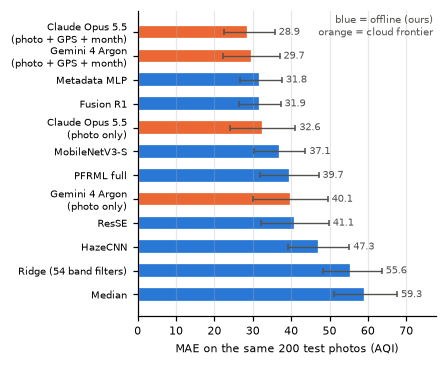

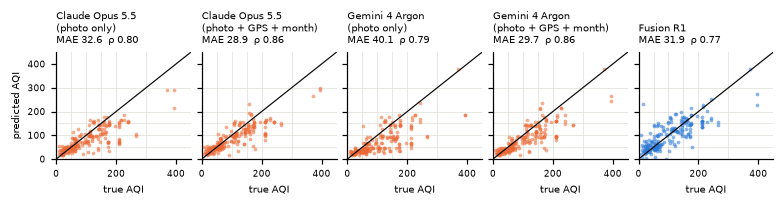

In [7]:
# Step 6: figures - MAE ranking (offline blue, cloud orange) and predicted vs true for the four agents and Fusion R1
s = frontier_summary
order = s.index[::-1]
fig, ax = plt.subplots(figsize=(3.5, 3.6))
ax.barh(range(len(order)), s.loc[order, 'mae'], color=[ORANGE if n in FRONTIER_COLS else BLUE for n in order], height=0.62, edgecolor='white', linewidth=1.5)
ax.errorbar(s.loc[order, 'mae'], range(len(order)), xerr=[s.loc[order, 'mae'] - s.loc[order, 'mae_ci_low'], s.loc[order, 'mae_ci_high'] - s.loc[order, 'mae']],
            fmt='none', ecolor=INK2, elinewidth=0.9, capsize=2)
for i, name in enumerate(order):
    ax.text(s.loc[name, 'mae_ci_high'] + 1, i, f"{s.loc[name, 'mae']:.1f}", va='center', fontsize=6.8, color=INK2)
ax.set_yticks(range(len(order)), [n.replace(' (', '\n(') if n in FRONTIER_COLS else n for n in order], fontsize=6.6)
ax.set_xlabel(f'MAE on the same {len(cmp)} test photos (AQI)', fontsize=7.5)
ax.tick_params(axis='x', labelsize=7)
ax.grid(axis='y', visible=False)
ax.set_xlim(0, s['mae_ci_high'].max() * 1.15)
ax.text(0.99, 0.99, 'blue = offline (ours)\norange = cloud frontier', transform=ax.transAxes, ha='right', va='top', fontsize=6.6, color=INK2)
fig.savefig(FIG / 'final_frontier_mae.png', bbox_inches='tight', facecolor='white')
plt.show()

panels = [CLAUDE_P, CLAUDE_M, GEMINI_P, GEMINI_M, 'Fusion R1']
fig, axes = plt.subplots(1, len(panels), figsize=(7.2, 1.95), sharex=True, sharey=True)
for ax, name in zip(axes, panels):
    ax.scatter(y_s, cmp[name], s=6, alpha=0.55, color=ORANGE if name in FRONTIER_COLS else BLUE, linewidths=0)
    ax.plot([0, 450], [0, 450], color=INK, linewidth=0.8)
    for edge in [50, 100, 150, 200, 300]:
        ax.axvline(edge, color='#e1e0d9', linewidth=0.5, zorder=0)
        ax.axhline(edge, color='#e1e0d9', linewidth=0.5, zorder=0)
    ax.set_title(f"{name.replace(' (', chr(10) + '(')}\nMAE {s.loc[name, 'mae']:.1f}  ρ {s.loc[name, 'srcc']:.2f}", fontsize=6.3, loc='left')
    ax.set(xlim=(0, 450), ylim=(0, 450))
    ax.tick_params(labelsize=6)
    ax.grid(False)
    ax.set_xlabel('true AQI', fontsize=6.5)
axes[0].set_ylabel('predicted AQI', fontsize=6.5)
fig.tight_layout(w_pad=0.4)
fig.savefig(FIG / 'final_frontier_scatter.png', bbox_inches='tight', facecolor='white')
plt.show()

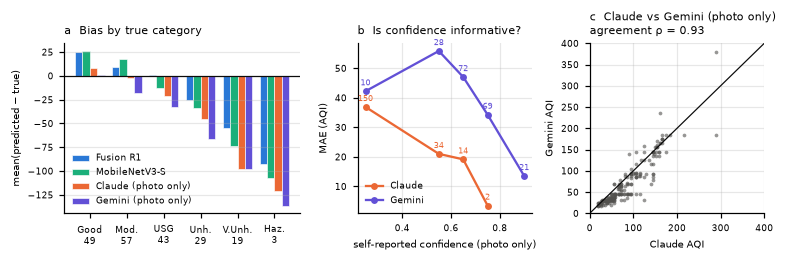

In [8]:
# Step 7: do the agents share our models' bias? is their self-reported confidence informative? do they agree with each other?
bins = pd.cut(cmp['pm25'], [0, 50, 100, 150, 200, 300, 1000], labels=['Good', 'Mod.', 'USG', 'Unh.', 'V.Unh.', 'Haz.'], include_lowest=True)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.45), gridspec_kw={'width_ratios': [1.35, 1, 1]})

ax = axes[0]
shown = {'Fusion R1': BLUE, 'MobileNetV3-S': AQUA, CLAUDE_P: ORANGE, GEMINI_P: VIOLET}
cats = list(bins.cat.categories)
width = 0.8 / len(shown)
for k, (name, color) in enumerate(shown.items()):
    bias = [np.mean(cmp.loc[bins == c, name] - cmp.loc[bins == c, 'pm25']) for c in cats]
    ax.bar(np.arange(len(cats)) + (k - (len(shown) - 1) / 2) * width, bias, width=width, color=color, edgecolor='white', linewidth=0.4,
           label=name.replace('Claude Opus 5.5', 'Claude').replace('Gemini 4 Argon', 'Gemini'))
ax.axhline(0, color=INK, linewidth=0.8)
counts = bins.value_counts().reindex(cats)
ax.set_xticks(range(len(cats)), [f'{c}\n{counts[c]}' for c in cats], fontsize=6)
ax.set_ylabel('mean(predicted − true)', fontsize=6.8)
ax.tick_params(axis='y', labelsize=6.2)
ax.grid(axis='x', visible=False)
ax.set_title('a  Bias by true category', fontsize=7.5, loc='left')
ax.legend(fontsize=5.6, frameon=False, loc='lower left')

ax = axes[1]
for agent, color in [('claude', ORANGE), ('gemini', VIOLET)]:
    sub = answers[(answers.agent == agent) & (answers.condition == 'image')].copy()
    sub['abs_err'] = (sub['aqi_pred'] - sub['pm25']).abs()
    grouped = sub.groupby(pd.cut(sub['confidence'], [0, 0.5, 0.6, 0.7, 0.8, 1.0], include_lowest=True), observed=True)['abs_err'].agg(['mean', 'size'])
    centers = [interval.mid for interval in grouped.index]
    ax.plot(centers, grouped['mean'], marker='o', markersize=3.5, linewidth=1.5, color=color, label=AGENT_LABEL[agent].split()[0])
    for x_, m_, n_ in zip(centers, grouped['mean'], grouped['size']):
        ax.text(x_, m_ + 2, str(n_), fontsize=5.2, color=color, ha='center')
ax.set_xlabel('self-reported confidence (photo only)', fontsize=6.6)
ax.set_ylabel('MAE (AQI)', fontsize=6.8)
ax.tick_params(labelsize=6.2)
ax.set_title('b  Is confidence informative?', fontsize=7.5, loc='left')
ax.legend(fontsize=5.8, frameon=False)

ax = axes[2]
ax.scatter(cmp[CLAUDE_P], cmp[GEMINI_P], s=6, alpha=0.6, color=INK2, linewidths=0)
ax.plot([0, 400], [0, 400], color=INK, linewidth=0.8)
ax.set_title(f'c  Claude vs Gemini (photo only)\nagreement ρ = {agreement:.2f}', fontsize=7.5, loc='left')
ax.set(xlim=(0, 400), ylim=(0, 400))
ax.set_xlabel('Claude AQI', fontsize=6.6)
ax.set_ylabel('Gemini AQI', fontsize=6.6)
ax.tick_params(labelsize=6.2)
fig.tight_layout(w_pad=0.9)
fig.savefig(FIG / 'final_frontier_extra.png', bbox_inches='tight', facecolor='white')
plt.show()

true AQI 49
   Claude       42  Blue sky with scattered clouds, distant buildings crisp with good contrast, minimal haze; slight whitish softening near horizon suggests low-moderate PM2.5.
   Claude +m    48  Clear blue sky with little haze in coastal Yokosuka in August; summer PM2.5 there is usually about 8–14 µg/m³.
true AQI 54
   Claude       38  Deep blue sky, crisp distant buildings and poles, strong shadows; minimal haze. Japanese urban street, typically low PM2.5.
   Claude +m    40  Clear deep-blue sky and sharp distant buildings in Niigata. July PM2.5 there is usually low, around 8–10 µg/m³.
true AQI 114
   Claude      105  Whitish overcast sky, distant trees and buildings look washed out with low contrast; a winter afternoon in southern Taiwan suggests moderate-to-elevated PM2.5.
   Claude +m    95  Overcast, slightly hazy distance; Pingtung in February often has elevated PM2.5 from winter stagnation and transported pollution, typically moderate.
true AQI 153
   Claude      1

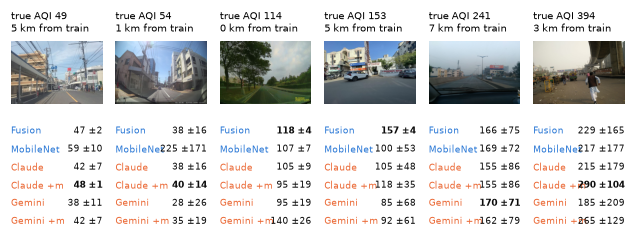

In [9]:
# Step 8: one photo per AQI category with every answer (bold = closest), and the agents' own reasons for those photos
cmp['bin'] = pd.cut(cmp['pm25'], [0, 50, 100, 150, 200, 300, 1000], labels=False, include_lowest=True)
picks = cmp.groupby('bin', group_keys=False).sample(1, random_state=7).sort_values('pm25').head(6)
shown = ['Fusion R1', 'MobileNetV3-S', CLAUDE_P, CLAUDE_M, GEMINI_P, GEMINI_M]
short = {'Fusion R1': 'Fusion', 'MobileNetV3-S': 'MobileNet', CLAUDE_P: 'Claude', CLAUDE_M: 'Claude +m', GEMINI_P: 'Gemini', GEMINI_M: 'Gemini +m'}
fig = plt.figure(figsize=(7.2, 2.55))
grid = fig.add_gridspec(2, len(picks), height_ratios=[1, 1.05], hspace=0.02, wspace=0.14)
for col, (idx, row) in enumerate(picks.iterrows()):
    ax = fig.add_subplot(grid[0, col])
    ax.imshow(Image.open(PROJECT_ROOT / 'datasets/test/images' / row['filename']).convert('RGB').resize((320, 220)))
    ax.set_title(f"true AQI {row['pm25']:.0f}\n{row['nearest_km']:.0f} km from train", fontsize=6.5, loc='left')
    ax.axis('off')
    tax = fig.add_subplot(grid[1, col])
    tax.axis('off')
    errors = {n: abs(row[n] - row['pm25']) for n in shown}
    for k, name in enumerate(shown):
        tax.text(0.0, 1.0 - k * 0.165, short[name], fontsize=5.6, color=BLUE if name in OUR_MODELS else ORANGE, va='top', transform=tax.transAxes)
        tax.text(1.0, 1.0 - k * 0.165, f"{row[name]:.0f} ±{errors[name]:.0f}", fontsize=5.6, color=INK, va='top', ha='right',
                 transform=tax.transAxes, fontweight='bold' if errors[name] == min(errors.values()) else None)
fig.savefig(FIG / 'final_frontier_samples.png', bbox_inches='tight', facecolor='white')
plt.show()

examples = picks[['image_id', 'pm25'] + shown + [f'reason | {c}' for c in [CLAUDE_P, CLAUDE_M, GEMINI_P, GEMINI_M]]]
examples.to_csv(FRONTIER / 'sample_examples.csv', index=False)
for _, row in examples.iterrows():
    print(f"true AQI {row['pm25']:.0f}")
    for c in [CLAUDE_P, CLAUDE_M]:
        print(f"   {short[c]:10s} {row[c]:>4.0f}  {row['reason | ' + c]}")

region share of test photos: {'Asia': 49.6, 'Europe': 27.7, 'North America': 9.6, 'Middle East': 4.9, 'Africa': 4.1, 'Latin America': 2.3, 'Oceania': 1.8}


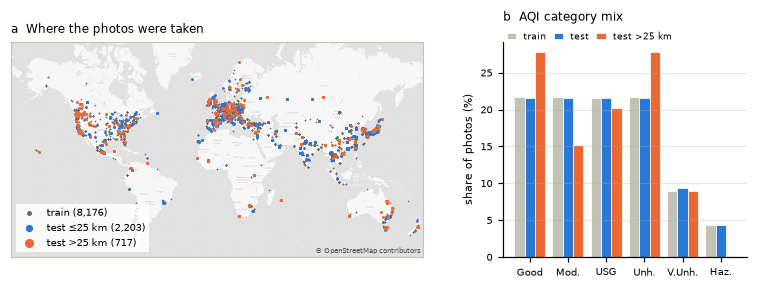

In [12]:
# PART B - WHERE AND WHY THE MODELS ERR. Step 9: where the photos are and how their AQI categories are distributed
# Basemap: OpenStreetMap standard tiles (zoom 3), desaturated and lightened to grey. Tiles are downloaded once and
# cached in outputs/osm_tiles/ (OSM tile policy: identify the client, keep requests light, show attribution).
import math
import urllib.request

R_EARTH = 6378137.0
TILE_DIR = PROJECT_ROOT / 'outputs' / 'osm_tiles'


def to_mercator(lon, lat):
    lon, lat = np.asarray(lon, float), np.clip(np.asarray(lat, float), -85.05, 85.05)
    return R_EARTH * np.radians(lon), R_EARTH * np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))


def tile_y(lat, z):
    return int((1 - math.asinh(math.tan(math.radians(lat))) / math.pi) / 2 * 2 ** z)


def osm_grey_basemap(lat_top=75, lat_bottom=-58, z=3, lighten=0.45):
    rows = range(tile_y(lat_top, z), tile_y(lat_bottom, z) + 1)
    canvas = Image.new('RGB', (256 * 2 ** z, 256 * len(rows)))
    for j, y in enumerate(rows):
        for x in range(2 ** z):
            path = TILE_DIR / str(z) / str(x) / f'{y}.png'
            if not path.exists():
                path.parent.mkdir(parents=True, exist_ok=True)
                request = urllib.request.Request(f'https://tile.openstreetmap.org/{z}/{x}/{y}.png',
                                                 headers={'User-Agent': 'acit4620-course-notebook/1.0 (static report figure)'})
                path.write_bytes(urllib.request.urlopen(request, timeout=30).read())
                time.sleep(0.2)
            canvas.paste(Image.open(path).convert('RGB'), (256 * x, 256 * j))
    grey = np.asarray(canvas.convert('L'), dtype=float) / 255
    grey = lighten + (1 - lighten) * grey  # wash towards white so the data points stand out
    world = 2 * math.pi * R_EARTH
    top = world / 2 - rows[0] / 2 ** z * world
    bottom = world / 2 - (rows[-1] + 1) / 2 ** z * world
    return grey, (-world / 2, world / 2, bottom, top)


basemap, extent = osm_grey_basemap()
far_df, near_df = test_df[test_df.gt25km], test_df[~test_df.gt25km]
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), gridspec_kw={'width_ratios': [1.9, 1]})
ax = axes[0]
ax.imshow(basemap, extent=extent, cmap='gray', vmin=0, vmax=1, interpolation='lanczos', zorder=0)
for frame, color, size, label in [(train_df, '#6b6a66', 1.2, f'train ({len(train_df):,})'), (near_df, BLUE, 2.5, f'test ≤25 km ({len(near_df):,})'),
                                  (far_df, ORANGE, 4, f'test >25 km ({len(far_df):,})')]:
    mx, my = to_mercator(frame.longitude, frame.latitude)
    ax.scatter(mx, my, s=size, color=color, linewidths=0, label=label, rasterized=True, zorder=2)
x0, y0 = to_mercator(-180, -58)
x1, y1 = to_mercator(180, 75)
ax.set(xlim=(x0, x1), ylim=(y0, y1), xticks=[], yticks=[])
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#c3c2b7')
ax.set_title('a  Where the photos were taken', fontsize=8, loc='left')
ax.legend(fontsize=6.3, loc='lower left', frameon=True, framealpha=0.85, edgecolor='none', markerscale=3)
ax.text(0.995, 0.01, '© OpenStreetMap contributors', transform=ax.transAxes, ha='right', va='bottom', fontsize=4.8, color=INK2)
ax = axes[1]
shares = {'train': train_df.aqi_bin, 'test': test_df.aqi_bin, 'test >25 km': far_df.aqi_bin}
for k, (name, color) in enumerate(zip(shares, [PALE, BLUE, ORANGE])):
    ax.bar(np.arange(6) + (k - 1) * 0.27, np.bincount(shares[name], minlength=6) / len(shares[name]) * 100, width=0.27, color=color,
           label=name, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(6), ['Good', 'Mod.', 'USG', 'Unh.', 'V.Unh.', 'Haz.'], fontsize=6.3)
ax.set_ylabel('share of photos (%)', fontsize=7)
ax.tick_params(axis='y', labelsize=6.5)
ax.set_title('b  AQI category mix', fontsize=8, loc='left', pad=14)
ax.legend(fontsize=6, frameon=False, ncol=3, loc='lower left', bbox_to_anchor=(0.0, 0.985), handlelength=1.0, columnspacing=0.8, borderaxespad=0)
ax.grid(axis='x', visible=False)
fig.tight_layout(w_pad=1.0)
fig.savefig(FIG / 'final_dataset.png', bbox_inches='tight', facecolor='white')
plt.show()
print('region share of test photos:', (test_df.region.value_counts(normalize=True) * 100).round(1).to_dict())

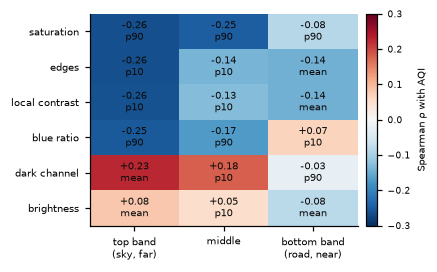

In [11]:
# Step 10: which haze filter, in which horizontal band, follows AQI? (notebook-2 band features, training photos only)
band = pd.read_csv('features/band_filter_features.csv')
band_train = band[band.split == 'train']
feature_cols = [c for c in band_train.columns if c.endswith(('_mean', '_p10', '_p90'))]
rho = band_train[feature_cols].corrwith(band_train.pm25, method='spearman')
rho_table = pd.DataFrame([dict(zip(['filter', 'band', 'stat'], name.rsplit('_', 2)), rho=value) for name, value in rho.items()])
rho_table['filter'] = rho_table['filter'].str.replace('_', ' ')
best = rho_table.loc[rho_table.groupby(['filter', 'band'])['rho'].apply(lambda v: v.abs().idxmax())]
grid_rho = best.pivot(index='filter', columns='band', values='rho')[['top', 'middle', 'bottom']]
grid_stat = best.pivot(index='filter', columns='band', values='stat')[['top', 'middle', 'bottom']]
order_f = grid_rho.abs().max(axis=1).sort_values(ascending=False).index
grid_rho, grid_stat = grid_rho.loc[order_f], grid_stat.loc[order_f]

fig, ax = plt.subplots(figsize=(3.4, 2.5))
image = ax.imshow(grid_rho.to_numpy(), cmap='RdBu_r', vmin=-0.3, vmax=0.3, aspect='auto')
for (r, c), value in np.ndenumerate(grid_rho.to_numpy()):
    ax.text(c, r, f'{value:+.2f}\n{grid_stat.iat[r, c]}', ha='center', va='center', fontsize=6.3, color=INK)
ax.set_xticks(range(3), ['top band\n(sky, far)', 'middle', 'bottom band\n(road, near)'], fontsize=6.5)
ax.set_yticks(range(len(grid_rho)), grid_rho.index, fontsize=6.8)
ax.grid(False)
bar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
bar.ax.tick_params(labelsize=6)
bar.set_label('Spearman ρ with AQI', fontsize=6.5)
fig.savefig(FIG / 'final_filter_corr.png', bbox_inches='tight', facecolor='white')
plt.show()

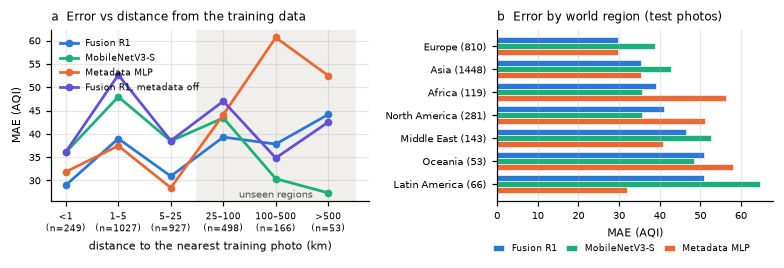

,photos,Fusion R1,MobileNetV3-S,Metadata MLP,Fusion R1 (metadata off)
dist_bin,,,,,
<1,249,29.0,36.0,31.8,36.1
1–5,1027,39.0,47.9,37.4,52.6
5–25,927,30.9,38.5,28.4,38.5
25–100,498,39.3,43.4,44.1,47.0
100–500,166,37.8,30.4,60.7,34.8
>500,53,44.2,27.3,52.5,42.5


In [14]:
# Step 11: how does the error change with distance to the nearest training photo, and across world regions?
y_t = test_df['pm25'].to_numpy(float)
DIST_EDGES = [0, 1, 5, 25, 100, 500, 20000]
DIST_LABELS = ['<1', '1–5', '5–25', '25–100', '100–500', '>500']
test_df['dist_bin'] = pd.cut(test_df['nearest_km'], DIST_EDGES, labels=DIST_LABELS, right=False)
dist_counts = test_df['dist_bin'].value_counts().reindex(DIST_LABELS)
line_models = {'Fusion R1': BLUE, 'MobileNetV3-S': AQUA, 'Metadata MLP': ORANGE, 'Fusion R1 (metadata off)': VIOLET}
error_by_distance = pd.DataFrame({name: test_df.assign(err=np.abs(test_df[name] - y_t)).groupby('dist_bin', observed=False)['err'].mean()
                                  for name in line_models}).reindex(DIST_LABELS)
error_by_distance.insert(0, 'photos', dist_counts)
error_by_distance.to_csv(PROJECT_ROOT / 'results' / 'error_by_distance.csv')

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), gridspec_kw={'width_ratios': [1.15, 1]})
ax = axes[0]
for name, color in line_models.items():
    ax.plot(range(len(DIST_LABELS)), error_by_distance[name], marker='o', markersize=4, linewidth=1.8, color=color,
            label=name.replace('Fusion R1 (metadata off)', 'Fusion R1, metadata off'))
ax.axvspan(2.5, 5.5, color=LIGHT_GRAY, zorder=0)
ax.text(4.0, error_by_distance[list(line_models)].min().min() - 1, 'unseen regions', fontsize=6.3, color=INK2, ha='center')
ax.set_xticks(range(len(DIST_LABELS)), [f'{l}\n(n={dist_counts[l]})' for l in DIST_LABELS], fontsize=6)
ax.set_xlabel('distance to the nearest training photo (km)', fontsize=7)
ax.set_ylabel('MAE (AQI)', fontsize=7)
ax.tick_params(axis='y', labelsize=6.5)
ax.set_title('a  Error vs distance from the training data', fontsize=8, loc='left')
ax.legend(fontsize=6, frameon=False, loc='upper left')

ax = axes[1]
regions = test_df.region.value_counts()
regions = regions[regions >= 40].index
region_mae = {name: test_df.assign(err=np.abs(test_df[name] - y_t)).groupby('region')['err'].mean() for name in list(line_models)[:3]}
order_r = region_mae['Fusion R1'].loc[regions].sort_values().index
for k, (name, color) in enumerate(list(line_models.items())[:3]):
    ax.barh(np.arange(len(order_r)) + (k - 1) * 0.26, region_mae[name].loc[order_r], height=0.26, color=color, label=name, edgecolor='white', linewidth=0.4)
ax.set_yticks(range(len(order_r)), [f'{r} ({(test_df.region == r).sum()})' for r in order_r], fontsize=6.3)
ax.invert_yaxis()
ax.set_xlabel('MAE (AQI)', fontsize=7)
ax.tick_params(axis='x', labelsize=6.5)
ax.grid(axis='y', visible=False)
ax.set_title('b  Error by world region (test photos)', fontsize=8, loc='left')
ax.legend(fontsize=6, frameon=False, loc='upper center', bbox_to_anchor=(0.45, -0.2), ncol=3, handlelength=1.2, columnspacing=1.0)
fig.tight_layout(w_pad=1.2)
fig.savefig(FIG / 'final_distance_region.png', bbox_inches='tight', facecolor='white')
plt.show()
error_by_distance.round(1)

In [15]:
# Step 12: rebuild the trained models from notebook-4 checkpoints (outputs/notebook4/checkpoints). The notebook-3 CNNs are
# declared again exactly as in notebooks 3 and 4; the repo models come from train.build_image_model.
CKPT = NB4 / 'checkpoints'


class HazeFilters(nn.Module):
    # RGB (3 channels) -> RGB + dark channel, saturation, brightness, Sobel edges, local contrast (8 channels)
    def forward(self, rgb):
        gray = rgb.mean(dim=1, keepdim=True)
        brightest = rgb.max(dim=1, keepdim=True).values
        darkest = rgb.min(dim=1, keepdim=True).values
        dark_channel = -F.max_pool2d(-darkest, kernel_size=7, stride=1, padding=3)
        saturation = (brightest - darkest) / (brightest + 1e-6)
        sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]], device=rgb.device, dtype=rgb.dtype).view(1, 1, 3, 3)
        edges = torch.sqrt(F.conv2d(gray, sobel_x, padding=1) ** 2 + F.conv2d(gray, sobel_x.transpose(2, 3), padding=1) ** 2)
        mean = F.avg_pool2d(gray, 7, stride=1, padding=3)
        local_contrast = (F.avg_pool2d(gray ** 2, 7, stride=1, padding=3) - mean ** 2).clamp(min=0).sqrt()
        return torch.cat([rgb, dark_channel, saturation, brightest, edges, local_contrast], dim=1)


def build_haze_cnn():
    return nn.Sequential(
        HazeFilters(),
        nn.Conv2d(8, 32, kernel_size=5, stride=2, padding=2), nn.BatchNorm2d(32), nn.ReLU(),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1))


class SqueezeExcite(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.weights = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(channels, channels // reduction), nn.ReLU(),
                                     nn.Linear(channels // reduction, channels), nn.Sigmoid())

    def forward(self, x):
        return x * self.weights(x).view(x.shape[0], -1, 1, 1)


class ResidualBlock(nn.Module):
    def __init__(self, channels, use_se=False):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.BatchNorm2d(channels), nn.LeakyReLU(0.1))
        self.se = SqueezeExcite(channels) if use_se else nn.Identity()
        self.pool = nn.MaxPool2d(3, stride=2, padding=1)

    def forward(self, x):
        return self.pool(x + self.se(self.conv(x)))


def build_resse():
    return nn.Sequential(
        HazeFilters(),
        nn.Conv2d(8, 64, 3, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.1),
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.1), nn.MaxPool2d(3, stride=2, padding=1),
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.1),
        nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.1), nn.MaxPool2d(3, stride=2, padding=1),
        ResidualBlock(128, use_se=True), ResidualBlock(128), ResidualBlock(128), ResidualBlock(128, use_se=True),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 512), nn.LeakyReLU(0.1), nn.Dropout(0.3),
        nn.Linear(512, 512), nn.LeakyReLU(0.1), nn.Linear(512, 1))


def repo_model(model_name, config, modality_dropout=None):
    overrides = {'model.name': model_name} | ({'pfrml.modality_dropout': modality_dropout} if modality_dropout is not None else {})
    return build_image_model(model_name, load_config(config, overrides=overrides))[0]


def load(model, checkpoint):
    state = torch.load(CKPT / checkpoint, map_location='cpu', weights_only=False)
    model.load_state_dict(state['state_dict'] if 'state_dict' in state else state)
    return model.eval()


# name -> (builder, checkpoint, example input, forward function returning AQI/100)
SMALL_IN, BIG_IN, META_IN = (3, 144, 192), (3, 224, 224), 5
MODEL_SPECS = {
    'Metadata MLP': (lambda: MetadataMLP(5, (64, 32)), 'metadata_mlp/model.pt', lambda m, x, z: m(z)),
    'HazeCNN': (build_haze_cnn, 'HazeCNN.pt', lambda m, x, z: m(x).squeeze(1)),
    'ResSE': (build_resse, 'ResSE.pt', lambda m, x, z: m(x).squeeze(1)),
    'MobileNetV3-S': (lambda: repo_model('mobilenetv3_s_pretrained', 'configs/default.yaml'), 'MobileNetV3-S.pt', lambda m, x, z: m(x)),
    'PFRML full': (lambda: repo_model('pfrml_mobilenetv3_s', 'configs/pfrml_all_toggles.yaml'), 'PFRML_full.pt', lambda m, x, z: m(x, targets=None).reg_pred),
    'Fusion R1': (lambda: repo_model('fusion_r1_mobilenetv3_s', 'configs/fusion_regression_only_neck.yaml', 0.0), 'Fusion_R1.pt',
                  lambda m, x, z: m(x, metadata=z).reg_pred),
}
models = {name: load(builder(), checkpoint) for name, (builder, checkpoint, _) in MODEL_SPECS.items()}
print({name: f'{sum(p.numel() for p in m.parameters()):,} params' for name, m in models.items()})

{'Metadata MLP': '2,497 params', 'HazeCNN': '596,321 params', 'ResSE': '1,192,865 params', 'MobileNetV3-S': '1,518,881 params', 'PFRML full': '2,107,331 params', 'Fusion R1': '2,016,611 params'}


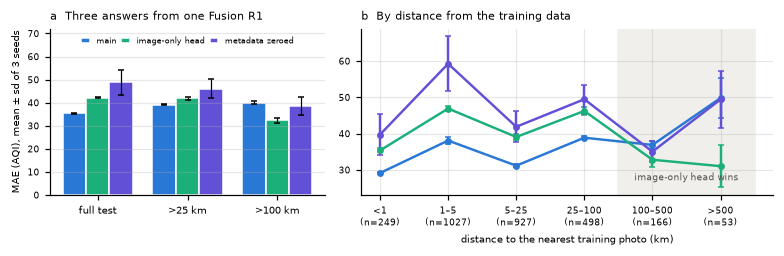

mean                   std             
split           >100 km >25 km   test >100 km >25 km  test
head                                                      
image-only head   32.36  42.00  42.22    1.17   0.62  0.17
main              40.00  39.21  35.39    0.58   0.22  0.25
metadata zeroed   38.51  46.12  48.85    3.77   3.95  5.43

,photos,main,image-only head,metadata zeroed
<1,249,29.1,35.4,39.7
1–5,1027,38.1,46.9,59.3
5–25,927,31.2,39.1,41.9
25–100,498,38.9,46.2,49.5
100–500,166,36.9,32.8,35.0
>500,53,49.8,31.0,49.4


In [17]:
# Step 13: Fusion R1 has three ways to answer - the main head (photo + GPS + month), its built-in image-only auxiliary head,
# and the main head with the metadata zeroed. Score all three for the three training seeds on the full test set.
test_loader = DataLoader(PM25Dataset(test_df, PROJECT_ROOT / 'datasets/test/images', transform=get_eval_transforms(224)), batch_size=64, num_workers=0)
heads = test_df[['image_id', 'station_id', 'pm25', 'nearest_km', 'gt25km', 'dist_bin']].copy()
with torch.no_grad():
    for suffix, seed in [('', 42), ('_seed43', 43), ('_seed44', 44)]:
        fusion = load(MODEL_SPECS['Fusion R1'][0](), f'Fusion_R1{suffix}.pt').to(device)
        main, aux, off = [], [], []
        for batch in test_loader:
            images, meta = batch.image.to(device), batch.metadata.to(device)
            out = fusion(images, metadata=meta)
            main.append(out.reg_pred.cpu())
            aux.append(out.aux_reg_pred.cpu())
            off.append(fusion(images, metadata=meta, metadata_off=True).reg_pred.cpu())
        for name, chunks in [('main', main), ('image-only head', aux), ('metadata zeroed', off)]:
            heads[f'{name} s{seed}'] = np.clip(torch.cat(chunks).numpy().reshape(-1) * 100, 0, None)
heads.to_csv(PROJECT_ROOT / 'results' / 'fusion_heads_predictions.csv', index=False)

HEADS = ['main', 'image-only head', 'metadata zeroed']
st_t = heads['station_id'].astype(str).to_numpy()
masks = {'test': np.ones(len(heads), bool), '>25 km': heads.gt25km.to_numpy(bool), '>100 km': heads.nearest_km.to_numpy() > 100}
head_rows = []
for head in HEADS:
    for seed in [42, 43, 44]:
        err = np.abs(heads[f'{head} s{seed}'] - y_t).to_numpy()
        for split, mask in masks.items():
            low, high = station_bootstrap_mae_ci(y_t[mask], heads[f'{head} s{seed}'].to_numpy()[mask], st_t[mask], n_boot=1000, seed=SEED)
            head_rows.append({'head': head, 'seed': seed, 'split': split, 'photos': int(mask.sum()), 'mae': err[mask].mean(), 'ci_low': low, 'ci_high': high})
head_results = pd.DataFrame(head_rows)
head_results.to_csv(PROJECT_ROOT / 'results' / 'fusion_heads_test.csv', index=False)
by_dist = pd.DataFrame({head: [np.mean([np.abs(heads[f'{head} s{s}'] - y_t)[heads.dist_bin == b].mean() for s in [42, 43, 44]]) for b in DIST_LABELS]
                        for head in HEADS}, index=DIST_LABELS)
by_dist_sd = pd.DataFrame({head: [np.std([np.abs(heads[f'{head} s{s}'] - y_t)[heads.dist_bin == b].mean() for s in [42, 43, 44]], ddof=1) for b in DIST_LABELS]
                           for head in HEADS}, index=DIST_LABELS)
by_dist.insert(0, 'photos', dist_counts.to_numpy())
by_dist.to_csv(PROJECT_ROOT / 'results' / 'fusion_heads_by_distance.csv')

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
summary = head_results.groupby(['head', 'split'])['mae'].agg(['mean', 'std']).reset_index()
for k, (head, color) in enumerate(zip(HEADS, [BLUE, AQUA, VIOLET])):
    part = summary[summary['head'] == head].set_index('split').loc[list(masks)]
    ax.bar(np.arange(3) + (k - 1) * 0.26, part['mean'], yerr=part['std'], width=0.26, color=color, label=head, edgecolor='white', capsize=2,
           error_kw={'elinewidth': 0.8})
ax.set_xticks(range(3), ['full test', '>25 km', '>100 km'], fontsize=6.5)
ax.set_ylabel('MAE (AQI), mean ± sd of 3 seeds', fontsize=6.5)
ax.tick_params(axis='y', labelsize=6.2)
ax.grid(axis='x', visible=False)
ax.set_title('a  Three answers from one Fusion R1', fontsize=7.5, loc='left')
ax.set_ylim(0, 72)
ax.legend(fontsize=5.5, frameon=False, loc='upper center', ncol=3, handlelength=1.0, columnspacing=0.6)
ax = axes[1]
for head, color in zip(HEADS, [BLUE, AQUA, VIOLET]):
    ax.errorbar(range(len(DIST_LABELS)), by_dist[head], yerr=by_dist_sd[head], marker='o', markersize=3.5, linewidth=1.6, color=color, capsize=2, label=head)
ax.axvspan(3.5, 5.5, color=LIGHT_GRAY, zorder=0)
ax.text(4.5, by_dist[HEADS].min().min() - 2, 'image-only head wins', fontsize=6, color=INK2, ha='center')
ax.set_xticks(range(len(DIST_LABELS)), [f'{l}\n(n={dist_counts[l]})' for l in DIST_LABELS], fontsize=5.8)
ax.set_xlabel('distance to the nearest training photo (km)', fontsize=6.6)
ax.tick_params(axis='y', labelsize=6.2)
ax.set_title('b  By distance from the training data', fontsize=7.5, loc='left')
fig.tight_layout(w_pad=1.0)
fig.savefig(FIG / 'final_fusion_heads.png', bbox_inches='tight', facecolor='white')
plt.show()
display(summary.pivot(index='head', columns='split', values=['mean', 'std']).round(2))
by_dist.round(1)

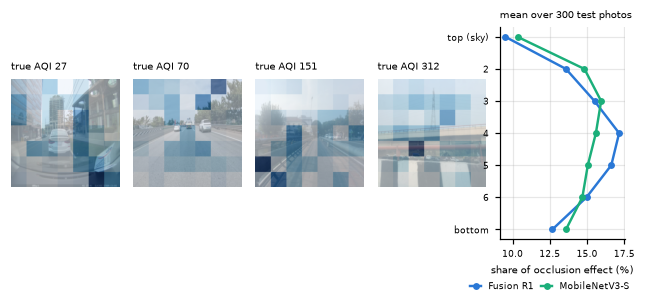

,Fusion R1,MobileNetV3-S
top (sky),9.5,10.3
row 2,13.6,14.8
row 3,15.5,15.9
row 4,17.1,15.6
row 5,16.6,15.0
row 6,15.0,14.7
bottom,12.7,13.6


In [19]:
# Step 14: where in the photo do the models look? Occlusion sensitivity: grey out each cell of a 7x7 grid (32 px patches of
# the 224 px input, filled with the ImageNet mean = 0 after normalisation) and record |change in predicted AQI|.
GRID, PATCH = 7, 224 // 7
occ_sample = test_df.sample(n=300, random_state=0).reset_index(drop=True)
occ_set = PM25Dataset(occ_sample, PROJECT_ROOT / 'datasets/test/images', transform=get_eval_transforms(224))
occ_images = torch.stack([occ_set[i].image for i in range(len(occ_set))])
occ_meta = torch.stack([occ_set[i].metadata for i in range(len(occ_set))])


@torch.no_grad()
def occlusion_maps(model, use_meta):
    model = model.to(device).eval()
    maps = np.zeros((len(occ_images), GRID, GRID), dtype=np.float32)
    for i in range(len(occ_images)):
        batch = occ_images[i:i + 1].repeat(GRID * GRID + 1, 1, 1, 1)
        for k in range(GRID * GRID):
            r, c = divmod(k, GRID)
            batch[k + 1, :, r * PATCH:(r + 1) * PATCH, c * PATCH:(c + 1) * PATCH] = 0.0
        batch = batch.to(device)
        pred = model(batch, metadata=occ_meta[i:i + 1].repeat(len(batch), 1).to(device)).reg_pred if use_meta else model(batch)
        pred = pred.float().cpu().numpy().reshape(-1) * 100
        maps[i] = np.abs(pred[1:] - pred[0]).reshape(GRID, GRID)
    return maps


occ = {'Fusion R1': occlusion_maps(models['Fusion R1'], True), 'MobileNetV3-S': occlusion_maps(models['MobileNetV3-S'], False)}
row_share = pd.DataFrame({name: m.mean(axis=(0, 2)) / m.mean(axis=(0, 2)).sum() for name, m in occ.items()},
                         index=['top (sky)', 'row 2', 'row 3', 'row 4', 'row 5', 'row 6', 'bottom'])
row_share.to_csv(PROJECT_ROOT / 'results' / 'occlusion_rows.csv')

examples_occ = [int(i) for i in np.argsort(occ_sample['pm25'].to_numpy())[[20, 110, 200, 290]]]
fig = plt.figure(figsize=(7.2, 2.5))
grid = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 1.15], wspace=0.12)
for col, i in enumerate(examples_occ):
    ax = fig.add_subplot(grid[0, col])
    ax.imshow(unnormalize_image(occ_images[i]).permute(1, 2, 0).numpy())
    heat = occ['Fusion R1'][i] / (occ['Fusion R1'][i].max() + 1e-6)
    ax.imshow(np.kron(heat, np.ones((PATCH, PATCH))), cmap='Blues', alpha=0.55, vmin=0, vmax=1)
    ax.set_title(f"true AQI {occ_sample.loc[i, 'pm25']:.0f}", fontsize=6.8, loc='left')
    ax.axis('off')
ax = fig.add_subplot(grid[0, 4])
for name, color in [('Fusion R1', BLUE), ('MobileNetV3-S', AQUA)]:
    ax.plot(row_share[name].to_numpy() * 100, range(GRID), marker='o', markersize=3.5, linewidth=1.6, color=color, label=name)
ax.invert_yaxis()
ax.set_yticks(range(GRID), ['top (sky)', '2', '3', '4', '5', '6', 'bottom'], fontsize=6.2)
ax.set_xlabel('share of occlusion effect (%)', fontsize=6.5)
ax.tick_params(axis='x', labelsize=6.2)
ax.legend(fontsize=6, frameon=False, loc='upper center', bbox_to_anchor=(0.4, -0.16), ncol=2, handlelength=1.2, columnspacing=0.8)
ax.set_title(f'mean over {len(occ_sample)} test photos', fontsize=6.8, loc='left')
fig.savefig(FIG / 'final_occlusion.png', bbox_inches='tight', facecolor='white')
plt.show()
(row_share * 100).round(1)

In [20]:
# PART C - ON-DEVICE FOOTPRINT. Step 15: what each model costs per photo on a CPU (batch size 1, PyTorch eager, M4 Pro).
# FLOPs from torch.utils.flop_counter (multiply-add = 2 FLOPs); activation memory = sum of every leaf-module output (fp32),
# an upper bound because a runtime frees most of them on the way.
from torch.utils.flop_counter import FlopCounterMode


def example_inputs(name):
    return torch.rand(1, *SMALL_IN) if name in ('HazeCNN', 'ResSE') else torch.randn(1, *BIG_IN), torch.randn(1, META_IN)


@torch.no_grad()
def footprint(name, runs=100):
    model = models[name].cpu().eval()
    forward = MODEL_SPECS[name][2]
    x, z = example_inputs(name)
    counter = FlopCounterMode(display=False)
    with counter:
        forward(model, x, z)
    sizes = []
    hooks = [m.register_forward_hook(lambda _m, _i, out: sizes.append(sum(t.numel() for t in (out if isinstance(out, (tuple, list)) else [out])
                                                                              if torch.is_tensor(t)) * 4 / 2 ** 20))
             for m in model.modules() if len(list(m.children())) == 0]
    forward(model, x, z)
    for h in hooks:
        h.remove()
    latency = {}
    for threads in (1, 4):
        torch.set_num_threads(threads)
        for _ in range(10):
            forward(model, x, z)
        times = []
        for _ in range(runs):
            start = time.perf_counter()
            forward(model, x, z)
            times.append((time.perf_counter() - start) * 1000)
        latency[threads] = statistics.median(times)
    params = sum(p.numel() for p in model.parameters())
    return {'model': name, 'params': params, 'gflops': counter.get_total_flops() / 1e9, 'size_fp32_mb': params * 4 / 2 ** 20,
            'size_fp16_mb': params * 2 / 2 ** 20, 'size_int8_mb': params / 2 ** 20, 'act_sum_mb': sum(sizes), 'act_max_mb': max(sizes),
            'cpu_ms_1t': latency[1], 'cpu_ms_4t': latency[4]}


foot = pd.DataFrame([footprint(name) for name in MODEL_SPECS]).set_index('model')
torch.set_num_threads(4)
foot.to_csv(PROJECT_ROOT / 'results' / 'mobile_footprint.csv')
foot.round(3)

,params,gflops,size_fp32_mb,size_fp16_mb,size_int8_mb,act_sum_mb,act_max_mb,cpu_ms_1t,cpu_ms_4t
model,,,,,,,,,
Metadata MLP,2497,0.000,0.010,0.005,0.002,0.001,0.000,0.010,0.009
HazeCNN,596321,1.873,2.275,1.137,0.569,20.569,1.688,9.385,7.096
ResSE,1192865,6.030,4.550,2.275,1.138,68.052,6.750,22.100,12.810
MobileNetV3-S,1518881,0.111,5.794,2.897,1.449,15.662,0.861,9.209,33.397
PFRML full,2107331,0.158,8.039,4.019,2.010,24.426,2.680,50.630,71.762
Fusion R1,2016611,0.158,7.693,3.846,1.923,24.422,2.680,11.531,37.244


In [21]:
# Step 16: does halving the weights to fp16 (what a phone runtime would ship) change accuracy? Full test set, fp32 vs fp16.
small_test = torch.from_numpy(np.stack([np.asarray(Image.open(PROJECT_ROOT / 'datasets/test/images' / f).convert('RGB').resize([192, 144]), dtype=np.uint8)
                                        for f in test_df.filename])).permute(0, 3, 1, 2)
fp16_rows = []
with torch.no_grad():
    for name in ['HazeCNN', 'ResSE', 'MobileNetV3-S', 'PFRML full', 'Fusion R1']:
        builder, checkpoint, forward = MODEL_SPECS[name]
        for dtype in [torch.float32, torch.float16]:
            model = load(builder(), checkpoint).to(device=device, dtype=dtype)
            if name in ('HazeCNN', 'ResSE'):
                pred = torch.cat([forward(model, (chunk.to(device).to(dtype) / 255), None).float().cpu() for chunk in small_test.split(256)])
            else:
                pred = torch.cat([forward(model, batch.image.to(device, dtype), batch.metadata.to(device, dtype)).float().cpu().reshape(-1)
                                  for batch in test_loader])
            pred = np.clip(pred.numpy() * 100, 0, None)
            fp16_rows.append({'model': name, 'dtype': str(dtype).replace('torch.', ''), 'test_mae': float(np.abs(pred - y_t).mean())})
fp16_check = pd.DataFrame(fp16_rows).pivot(index='model', columns='dtype', values='test_mae')
fp16_check['difference'] = fp16_check['float16'] - fp16_check['float32']
fp16_check.to_csv(PROJECT_ROOT / 'results' / 'mobile_fp16_check.csv')
fp16_check.round(3)

dtype,float16,float32,difference
model,,,
Fusion R1,35.675,35.648,0.026
HazeCNN,51.396,51.398,-0.003
MobileNetV3-S,41.758,41.770,-0.012
PFRML full,44.170,44.134,0.037
ResSE,44.994,45.104,-0.110


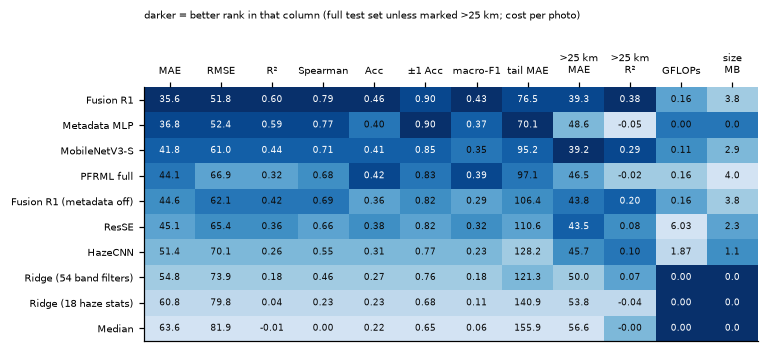

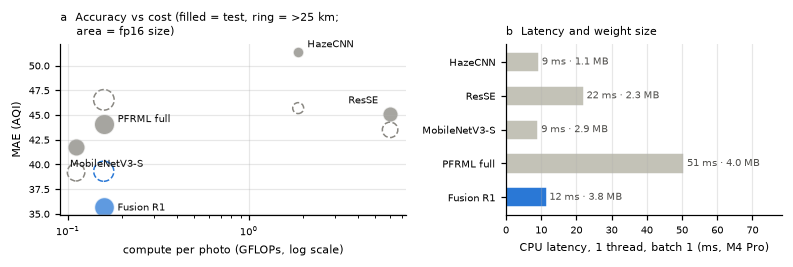

In [23]:
# Step 17: the scorecard (every model x every metric, darker = better rank) and accuracy vs on-device cost
board = pd.read_csv(NB4 / 'leaderboard.csv', index_col=0)
metric_cols = {'test MAE': ('MAE', False), 'RMSE': ('RMSE', False), 'R2': ('R²', True), 'SRCC': ('Spearman', True), 'Acc': ('Acc', True),
               '±1 Acc': ('±1 Acc', True), 'Macro-F1': ('macro-F1', True), 'tail MAE (AQI>200)': ('tail MAE', False),
               '>25km MAE': ('>25 km\nMAE', False), '>25km R2': ('>25 km\nR²', True)}
card = board[list(metric_cols)].copy()
cost_of = lambda m, col: foot.loc['Fusion R1' if m.startswith('Fusion') else m, col] if (m in foot.index or m.startswith('Fusion')) else 0.0
card['GFLOPs'] = [cost_of(m, 'gflops') for m in card.index]
card['fp16 MB'] = [cost_of(m, 'size_fp16_mb') for m in card.index]
metric_cols |= {'GFLOPs': ('GFLOPs', False), 'fp16 MB': ('size\nMB', False)}
ranks = pd.DataFrame({c: card[c].rank(ascending=not metric_cols[c][1], method='min') for c in card.columns})
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.imshow(ranks.to_numpy(), cmap='Blues_r', vmin=1, vmax=len(card) + 2, aspect='auto')
for (r, c), value in np.ndenumerate(card.to_numpy()):
    two_dp = card.columns[c] in ('R2', 'SRCC', 'Acc', '±1 Acc', 'Macro-F1', '>25km R2', 'GFLOPs')
    ax.text(c, r, f'{value:.2f}' if two_dp else f'{value:.1f}', ha='center', va='center', fontsize=6.2, color='white' if ranks.iat[r, c] <= 3 else INK)
ax.set_xticks(range(len(card.columns)), [metric_cols[c][0] for c in card.columns], fontsize=6.4)
ax.set_yticks(range(len(card)), card.index, fontsize=6.6)
ax.xaxis.tick_top()
ax.grid(False)
ax.set_title('darker = better rank in that column (full test set unless marked >25 km; cost per photo)', fontsize=6.8, loc='left', pad=22)
fig.savefig(FIG / 'final_scorecard.png', bbox_inches='tight', facecolor='white')
plt.show()

cnn_names = ['HazeCNN', 'ResSE', 'MobileNetV3-S', 'PFRML full', 'Fusion R1']
label_offset = {'MobileNetV3-S': (-4, -13), 'PFRML full': (9, 1), 'Fusion R1': (9, -2), 'ResSE': (-8, 7)}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.5), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
for name in cnn_names:
    color = BLUE if name == 'Fusion R1' else GRAY
    ax.scatter(foot.loc[name, 'gflops'], board.loc[name, 'test MAE'], s=foot.loc[name, 'size_fp16_mb'] * 45, color=color, alpha=0.75, edgecolor='white')
    ax.scatter(foot.loc[name, 'gflops'], board.loc[name, '>25km MAE'], s=foot.loc[name, 'size_fp16_mb'] * 45, facecolor='none', edgecolor=color, linestyle='--')
    ax.annotate(name, (foot.loc[name, 'gflops'], board.loc[name, 'test MAE']), xytext=label_offset.get(name, (6, 3)), textcoords='offset points',
                fontsize=6.3, color=INK, ha='right' if name == 'ResSE' else 'left')
ax.set_xscale('log')
ax.set_xlabel('compute per photo (GFLOPs, log scale)', fontsize=7)
ax.set_ylabel('MAE (AQI)', fontsize=7)
ax.tick_params(labelsize=6.5)
ax.set_title('a  Accuracy vs cost (filled = test, ring = >25 km;\n    area = fp16 size)', fontsize=7.5, loc='left')
ax = axes[1]
order_c = cnn_names[::-1]
ax.barh(range(len(order_c)), foot.loc[order_c, 'cpu_ms_1t'], color=[BLUE if n == 'Fusion R1' else PALE for n in order_c], height=0.6, edgecolor='white')
for i, n in enumerate(order_c):
    ax.text(foot.loc[n, 'cpu_ms_1t'] + 0.8, i, f"{foot.loc[n, 'cpu_ms_1t']:.0f} ms · {foot.loc[n, 'size_fp16_mb']:.1f} MB", va='center', fontsize=6.3, color=INK2)
ax.set_yticks(range(len(order_c)), order_c, fontsize=6.6)
ax.set_xlabel('CPU latency, 1 thread, batch 1 (ms, M4 Pro)', fontsize=7)
ax.tick_params(axis='x', labelsize=6.5)
ax.set_xlim(0, foot.loc[cnn_names, 'cpu_ms_1t'].max() * 1.55)
ax.grid(axis='y', visible=False)
ax.set_title('b  Latency and weight size', fontsize=7.5, loc='left')
fig.tight_layout(w_pad=1.2)
fig.savefig(FIG / 'final_footprint.png', bbox_inches='tight', facecolor='white')
plt.show()

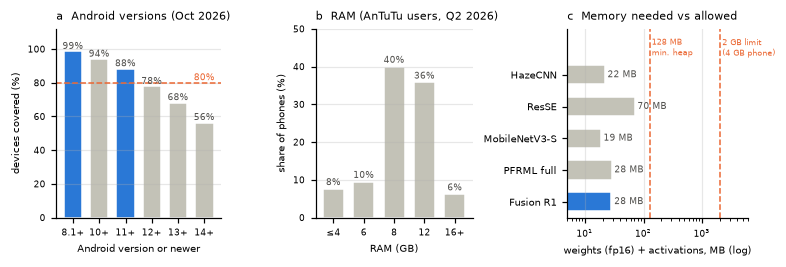

,quantity,value,source,date
0,people 10+ owning a mobile phone,84%,ITU Facts and Figures 2026,Oct 2026
1,people using their own smartphone for mobile i...,4.6 bn (56%),GSMA State of Mobile Internet Connectivity 2026,Sep 2026
2,smartphone subscriptions / all mobile subscrip...,7.41 bn / 8.83 bn,Ericsson Mobility Report Nov 2025,Nov 2025
3,share of active smartphones that are iPhones,~25%,"Counterpoint, active installed base",Feb 2026
4,mobile web page views Android / iOS,72.4% / 27.6%,StatCounter,Oct 2026
5,average RAM of NEW phones sold,8.4 GB,Counterpoint,Dec 2025
6,RAM of AnTuTu-benchmarked phones <=4 / 6 / 8 /...,7.6 / 9.5 / 40.0 / 35.8 / 6.2 %,AnTuTu Q2 2026 (enthusiast-biased),Jul 2026
7,smartphone replacement cycle,43 months,Counterpoint,Nov 2025
8,smartphone shipments Q3 2026 (memory price shock),-22% year on year,IDC via FoneArena,Oct 2026
9,Android 8.1+ / 10+ / 11+ / 12+ / 13+ / 14+,98.6 / 94.0 / 88.3 / 77.8 / 68.2 / 56.4 %,"Google Play devices, heise",Oct 2026


In [24]:
# Step 18: the phones people actually have. Public figures (read at the source, accessed 2026-11-21); every row keeps its source.
# No public source gives the RAM of phones IN USE (Google keeps it inside Play Console), so the RAM rows are a biased proxy.
market = pd.DataFrame([
    ('people 10+ owning a mobile phone', '84%', 'ITU Facts and Figures 2026', 'Oct 2026'),
    ('people using their own smartphone for mobile internet', '4.6 bn (56%)', 'GSMA State of Mobile Internet Connectivity 2026', 'Sep 2026'),
    ('smartphone subscriptions / all mobile subscriptions', '7.41 bn / 8.83 bn', 'Ericsson Mobility Report Nov 2025', 'Nov 2025'),
    ('share of active smartphones that are iPhones', '~25%', 'Counterpoint, active installed base', 'Feb 2026'),
    ('mobile web page views Android / iOS', '72.4% / 27.6%', 'StatCounter', 'Oct 2026'),
    ('average RAM of NEW phones sold', '8.4 GB', 'Counterpoint', 'Dec 2025'),
    ('RAM of AnTuTu-benchmarked phones <=4 / 6 / 8 / 12 / 16+ GB', '7.6 / 9.5 / 40.0 / 35.8 / 6.2 %', 'AnTuTu Q2 2026 (enthusiast-biased)', 'Jul 2026'),
    ('smartphone replacement cycle', '43 months', 'Counterpoint', 'Nov 2025'),
    ('smartphone shipments Q3 2026 (memory price shock)', '-22% year on year', 'IDC via FoneArena', 'Oct 2026'),
    ('Android 8.1+ / 10+ / 11+ / 12+ / 13+ / 14+', '98.6 / 94.0 / 88.3 / 77.8 / 68.2 / 56.4 %', 'Google Play devices, heise', 'Oct 2026'),
    ('iPhones on iOS 26 (A13 or newer, Neural Engine)', '79%', 'Apple App Store support', 'Jun 2026'),
    ('Play devices with Vulkan 1.1+ / OpenGL ES 3.2', '88.8% / 98.2%', 'Android distribution dashboard', 'Nov 2025'),
    ('minimum Java heap per app (xxhdpi / xxxhdpi screens)', '128 / 256 MB', 'Android 16 CDD 3.7', '2026'),
    ('app memory limit on a 4 GB phone (Android 17 memory limiter)', '2,048 MiB', 'AOSP memory limiter', '2026'),
    ('LiteRT minimum Android SDK (CPU) / NPU delegate', 'API 21-24 / API 31 + arm64', 'Google LiteRT docs', '2026'),
    ('MobileNetV3-Small fp32 latency, one big core, Pixel 1', '15.8 ms', 'Howard et al., ICCV 2019', '2019'),
    ('AI Benchmark score Snapdragon 680 vs Snapdragon 8 Elite', '92 vs 20,726', 'ETH Zurich AI Benchmark ranking', 'Nov 2026'),
    ('a phone at the 75th percentile of performance', 'Galaxy A24 (Helio G99, 2x A76 + 6x A55, 4-8 GB)', 'Russell, Performance Inequality Gap 2026', 'Nov 2025'),
], columns=['quantity', 'value', 'source', 'date'])
market.to_csv(PROJECT_ROOT / 'results' / 'phone_market_facts.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5), gridspec_kw={'width_ratios': [1.05, 1, 1.15]})
ax = axes[0]
versions, share = ['8.1+', '10+', '11+', '12+', '13+', '14+'], [98.6, 94.0, 88.3, 77.8, 68.2, 56.4]
ax.bar(range(6), share, color=[BLUE if v in ('8.1+', '11+') else PALE for v in versions], edgecolor='white', width=0.7)
for i, value in enumerate(share):
    ax.text(i, value + 1.5, f'{value:.0f}%', ha='center', fontsize=6, color=INK2)
ax.axhline(80, color=ORANGE, linewidth=1, linestyle='--')
ax.text(5.4, 81.5, '80%', fontsize=6, color=ORANGE, ha='right')
ax.set_xticks(range(6), versions, fontsize=6.2)
ax.set_xlabel('Android version or newer', fontsize=6.6)
ax.set_ylim(0, 112)
ax.set_ylabel('devices covered (%)', fontsize=6.8)
ax.tick_params(axis='y', labelsize=6)
ax.grid(axis='x', visible=False)
ax.set_title('a  Android versions (Oct 2026)', fontsize=7.4, loc='left')
ax = axes[1]
tiers, ram = ['≤4', '6', '8', '12', '16+'], [7.6, 9.5, 40.0, 35.8, 6.2]
ax.bar(range(5), ram, color=PALE, edgecolor='white', width=0.7)
for i, value in enumerate(ram):
    ax.text(i, value + 1, f'{value:.0f}%', ha='center', fontsize=6, color=INK2)
ax.set_xticks(range(5), tiers, fontsize=6.2)
ax.set_xlabel('RAM (GB)', fontsize=6.6)
ax.set_ylabel('share of phones (%)', fontsize=6.8)
ax.tick_params(axis='y', labelsize=6)
ax.set_ylim(0, 50)
ax.grid(axis='x', visible=False)
ax.set_title('b  RAM (AnTuTu users, Q2 2026)', fontsize=7.4, loc='left')
ax = axes[2]
need = foot.loc[cnn_names, 'size_fp16_mb'] + foot.loc[cnn_names, 'act_sum_mb']
ax.barh(range(5), need, color=[BLUE if n == 'Fusion R1' else PALE for n in cnn_names], height=0.6, edgecolor='white')
for i, value in enumerate(need):
    ax.text(value * 1.12, i, f'{value:.0f} MB', va='center', fontsize=6, color=INK2)
for value, label in [(128, '128 MB\nmin. heap'), (2048, '2 GB limit\n(4 GB phone)')]:
    ax.axvline(value, color=ORANGE, linewidth=1, linestyle='--')
    ax.text(value * 1.08, -0.85, label, fontsize=5.3, color=ORANGE, ha='left', va='center')
ax.set_xscale('log')
ax.set_xlim(5, 6000)
ax.set_yticks(range(5), cnn_names, fontsize=6.3)
ax.set_ylim(4.5, -1.45)
ax.set_xlabel('weights (fp16) + activations, MB (log)', fontsize=6.6)
ax.tick_params(axis='x', labelsize=6)
ax.grid(axis='y', visible=False)
ax.set_title('c  Memory needed vs allowed', fontsize=7.4, loc='left')
fig.tight_layout(w_pad=0.8)
fig.savefig(FIG / 'final_devices.png', bbox_inches='tight', facecolor='white')
plt.show()
market

['final_dataset.png', 'final_devices.png', 'final_distance_region.png', 'final_filter_corr.png', 'final_footprint.png', 'final_frontier_extra.png', 'final_frontier_mae.png', 'final_frontier_samples.png', 'final_frontier_scatter.png', 'final_fusion_heads.png', 'final_haze_filters.png', 'final_nb4_confusion_top5.png', 'final_nb4_mae_comparison.png', 'final_nb4_paired_bootstrap.png', 'final_nb4_per_bin_error.png', 'final_nb4_pred_vs_true.png', 'final_nb4_seed_robustness.png', 'final_nb4_training_curves.png', 'final_occlusion.png', 'final_pipeline.png', 'final_scorecard.png']


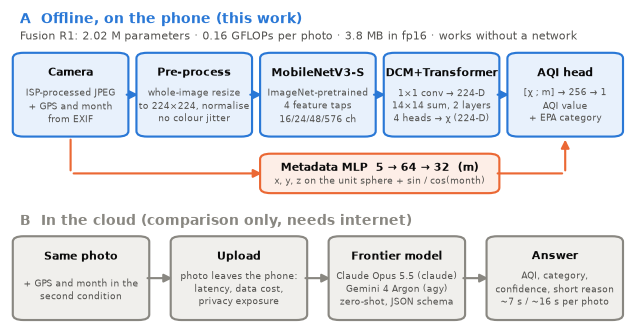

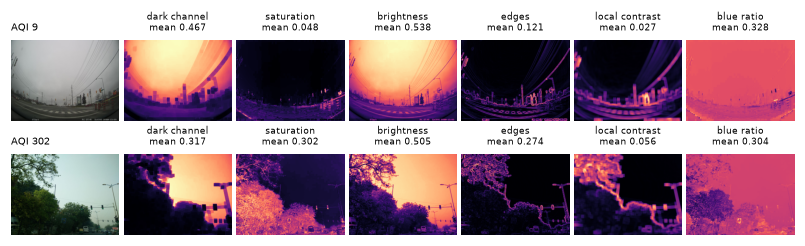

In [25]:
# PART D - REPORT FIGURES. Step 19: pipeline diagram, the haze-filter figure (notebook-2 filters) and notebook-4 figures.
def box(ax, x, y, w, h, title, body, face=LIGHT_BLUE, edge=BLUE):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.012,rounding_size=0.018', facecolor=face, edgecolor=edge, linewidth=1.4))
    ax.text(x + w / 2, y + h - 0.035, title, ha='center', va='top', fontsize=7.3, fontweight='bold', color=INK)
    ax.text(x + w / 2, y + h / 2 - 0.035, body, ha='center', va='center', fontsize=6.2, color=INK2, linespacing=1.35)


def arrow(ax, start, end, color=BLUE, style='-|>'):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle=style, mutation_scale=11, color=color, linewidth=1.4))


fig, ax = plt.subplots(figsize=(7.2, 3.7))
ax.set_xlim(-0.015, 1.015)
ax.set_ylim(-0.025, 1)
ax.axis('off')
ax.text(0.0, 0.995, 'A  Offline, on the phone (this work)', fontsize=9, fontweight='bold', color=BLUE, va='top')
ax.text(0.0, 0.935, f"Fusion R1: {foot.loc['Fusion R1', 'params'] / 1e6:.2f} M parameters · {foot.loc['Fusion R1', 'gflops']:.2f} GFLOPs per photo · "
        f"{foot.loc['Fusion R1', 'size_fp16_mb']:.1f} MB in fp16 · works without a network", fontsize=7, color=INK2, va='top')
y, h, w = 0.60, 0.25, 0.17
stages = [(0.0, 'Camera', 'ISP-processed JPEG\n+ GPS and month\nfrom EXIF'), (0.2075, 'Pre-process', 'whole-image resize\nto 224×224, normalise\nno colour jitter'),
          (0.415, 'MobileNetV3-S', 'ImageNet-pretrained\n4 feature taps\n16/24/48/576 ch'), (0.6225, 'DCM+Transformer', '1×1 conv → 224-D\n14×14 sum, 2 layers\n4 heads → χ (224-D)'),
          (0.83, 'AQI head', '[χ ; m] → 256 → 1\nAQI value\n+ EPA category')]
for x, title, body in stages:
    box(ax, x, y, w, h, title, body)
for (x1, *_), (x2, *_) in zip(stages[:-1], stages[1:]):
    arrow(ax, (x1 + w + 0.004, y + h / 2), (x2 - 0.004, y + h / 2))
mx, my, mw, mh = 0.415, 0.415, 0.3775, 0.105
ax.add_patch(FancyBboxPatch((mx, my), mw, mh, boxstyle='round,pad=0.012,rounding_size=0.018', facecolor=LIGHT_ORANGE, edgecolor=ORANGE, linewidth=1.4))
ax.text(mx + mw / 2, my + mh * 0.68, 'Metadata MLP  5 → 64 → 32  (m)', ha='center', va='center', fontsize=7.3, fontweight='bold', color=INK)
ax.text(mx + mw / 2, my + mh * 0.27, 'x, y, z on the unit sphere + sin / cos(month)', ha='center', va='center', fontsize=6.2, color=INK2)
arrow(ax, (0.085, y - 0.012), (0.085, my + mh / 2), color=ORANGE, style='-')
arrow(ax, (0.085, my + mh / 2), (mx - 0.004, my + mh / 2), color=ORANGE)
arrow(ax, (mx + mw + 0.004, my + mh / 2), (0.915, my + mh / 2), color=ORANGE, style='-')
arrow(ax, (0.915, my + mh / 2), (0.915, y - 0.012), color=ORANGE)
ax.text(0.0, 0.335, 'B  In the cloud (comparison only, needs internet)', fontsize=9, fontweight='bold', color=GRAY, va='top')
y2, h2, w2 = 0.0, 0.25, 0.205
cloud = [(0.0, 'Same photo', '+ GPS and month in the\nsecond condition'), (0.265, 'Upload', 'photo leaves the phone:\nlatency, data cost,\nprivacy exposure'),
         (0.53, 'Frontier model', 'Claude Opus 5.5 (claude)\nGemini 4 Argon (agy)\nzero-shot, JSON schema'),
         (0.795, 'Answer', f"AQI, category,\nconfidence, short reason\n~{answers[answers.agent == 'claude'].seconds.median():.0f} s / "
                           f"~{answers[answers.agent == 'gemini'].seconds.median():.0f} s per photo")]
for x, title, body in cloud:
    box(ax, x, y2, w2, h2, title, body, face=LIGHT_GRAY, edge=GRAY)
for (x1, *_), (x2, *_) in zip(cloud[:-1], cloud[1:]):
    arrow(ax, (x1 + w2 + 0.004, y2 + h2 / 2), (x2 - 0.004, y2 + h2 / 2), color=GRAY)
fig.savefig(FIG / 'final_pipeline.png', bbox_inches='tight', facecolor='white')
plt.show()

# haze filters on the same two training photos as notebook 2 (one Good, one Hazardous)
from scipy import ndimage
meta2 = pd.read_csv('features/clean_metadata.csv')
filter_examples = [meta2[(meta2.split == 'train') & (meta2.pm25_bin == b)].sample(1, random_state=1).iloc[0] for b in ['0–50', '301–600']]
FILTERS = {
    'dark channel': lambda rgb: ndimage.minimum_filter(rgb.min(axis=2), size=7),
    'saturation': lambda rgb: (rgb.max(axis=2) - rgb.min(axis=2)) / (rgb.max(axis=2) + 1e-6),
    'brightness': lambda rgb: rgb.max(axis=2),
    'edges': lambda rgb: np.hypot(ndimage.sobel(rgb.mean(axis=2), axis=0), ndimage.sobel(rgb.mean(axis=2), axis=1)),
    'local contrast': lambda rgb: np.sqrt(np.clip(ndimage.uniform_filter(rgb.mean(axis=2) ** 2, 7) - ndimage.uniform_filter(rgb.mean(axis=2), 7) ** 2, 0, None)),
    'blue ratio': lambda rgb: rgb[:, :, 2] / (rgb.sum(axis=2) + 1e-6),
}
fig, axes = plt.subplots(2, len(FILTERS) + 1, figsize=(7.2, 2.25))
for r, example in enumerate(filter_examples):
    rgb = np.asarray(Image.open(PROJECT_ROOT / 'datasets/train/images' / example.filename).convert('RGB').resize((256, 192)), dtype=np.float32) / 255
    axes[r, 0].imshow(rgb)
    axes[r, 0].set_title(f'AQI {example.pm25:.0f}', fontsize=6.8, loc='left')
    for c, (name, apply_filter) in enumerate(FILTERS.items(), start=1):
        response = apply_filter(rgb)
        axes[r, c].imshow(response, cmap='magma')
        axes[r, c].set_title(f'{name}\nmean {response.mean():.3f}', fontsize=5.6)
for ax in axes.ravel():
    ax.axis('off')
fig.tight_layout(pad=0.3)
fig.savefig(FIG / 'final_haze_filters.png', bbox_inches='tight', facecolor='white')
plt.show()

for name in ['mae_comparison', 'pred_vs_true', 'per_bin_error', 'paired_bootstrap', 'seed_robustness', 'confusion_top5', 'training_curves']:
    shutil.copy2(NB4 / f'{name}.png', FIG / f'final_nb4_{name}.png')
print(sorted(p.name for p in FIG.glob('final_*.png')))

In [27]:
# Step 20: the numbers the report quotes, in one place
fs, ft = frontier_summary, frontier_tests.set_index('comparison')
fusion_ms = foot.loc['Fusion R1', 'cpu_ms_1t']
claude_s, gemini_s = answers[answers.agent == 'claude'].seconds.median(), answers[answers.agent == 'gemini'].seconds.median()


def head_mae(head, split):
    return summary[(summary['head'] == head) & (summary['split'] == split)]['mean'].item()


lines = [
    f"Frontier sample: {len(cmp)} photos, {cmp.station_id.nunique()} stations, {int(far_s.sum())} >25 km; categories {np.bincount(cmp.aqi_bin, minlength=6).tolist()}",
    *[f"  {name:40s} MAE {fs.loc[name, 'mae']:.1f} [{fs.loc[name, 'mae_ci_low']:.1f}, {fs.loc[name, 'mae_ci_high']:.1f}]  R2 {fs.loc[name, 'r2']:.2f}  "
      f"rho {fs.loc[name, 'srcc']:.2f}  bias {fs.loc[name, 'bias']:+.1f}  vs Fusion {fs.loc[name, 'diff_vs_fusion']:+.1f} "
      f"[{fs.loc[name, 'diff_ci_low']:+.1f}, {fs.loc[name, 'diff_ci_high']:+.1f}]" for name in fs.index],
    f"Metadata helps Claude by {-ft.loc[f'{CLAUDE_M}  minus  {CLAUDE_P}', 'MAE difference']:.1f} and Gemini by {-ft.loc[f'{GEMINI_M}  minus  {GEMINI_P}', 'MAE difference']:.1f} MAE",
    f"Claude vs Gemini agreement rho {agreement:.2f}",
    f"Median answer time: Claude {claude_s:.1f} s, Gemini {gemini_s:.1f} s; Fusion R1 {fusion_ms:.0f} ms on one laptop CPU core "
    f"-> {claude_s * 1000 / fusion_ms:.0f}x / {gemini_s * 1000 / fusion_ms:.0f}x faster offline",
    f"Fusion R1 heads (3 seeds): main {head_mae('main', 'test'):.1f}, image-only {head_mae('image-only head', 'test'):.1f} on the test set; "
    f">100 km main {head_mae('main', '>100 km'):.1f} vs image-only {head_mae('image-only head', '>100 km'):.1f}",
    f"Occlusion share, top row (sky) {row_share.loc['top (sky)', 'Fusion R1'] * 100:.1f}%, rows 3-5 {row_share.loc[['row 3', 'row 4', 'row 5'], 'Fusion R1'].sum() * 100:.1f}%",
    f"Footprint Fusion R1: {foot.loc['Fusion R1', 'params']:,} params, {foot.loc['Fusion R1', 'gflops']:.3f} GFLOPs, {foot.loc['Fusion R1', 'size_fp16_mb']:.2f} MB fp16, "
    f"{foot.loc['Fusion R1', 'size_int8_mb']:.2f} MB int8, activations <= {foot.loc['Fusion R1', 'act_sum_mb']:.1f} MB, {fusion_ms:.1f} ms (1 thread)",
    f"fp16 changes test MAE by at most {fp16_check['difference'].abs().max():.2f}",
    f"FLOPs vs MobileNetV3-S: HazeCNN {foot.loc['HazeCNN', 'gflops'] / foot.loc['MobileNetV3-S', 'gflops']:.0f}x, "
    f"ResSE {foot.loc['ResSE', 'gflops'] / foot.loc['MobileNetV3-S', 'gflops']:.0f}x",
]
print('\n'.join(lines))

Frontier sample: 200 photos, 150 stations, 39 >25 km; categories [49, 57, 43, 29, 19, 3]
  Claude Opus 5.5 (photo + GPS + month)    MAE 28.9 [22.4, 35.8]  R2 0.67  rho 0.86  bias -15.4  vs Fusion -3.1 [-8.4, +2.0]
  Gemini 4 Argon (photo + GPS + month)     MAE 29.7 [22.3, 37.0]  R2 0.63  rho 0.86  bias -19.7  vs Fusion -2.2 [-7.9, +3.3]
  Metadata MLP                             MAE 31.8 [26.5, 37.6]  R2 0.64  rho 0.79  bias +0.4  vs Fusion -0.1 [-3.7, +3.8]
  Fusion R1                                MAE 31.9 [26.4, 37.3]  R2 0.61  rho 0.77  bias -1.3  vs Fusion +0.0 [+0.0, +0.0]
  Claude Opus 5.5 (photo only)             MAE 32.6 [24.0, 41.1]  R2 0.54  rho 0.80  bias -20.9  vs Fusion +0.7 [-5.8, +7.0]
  MobileNetV3-S                            MAE 37.1 [30.4, 43.7]  R2 0.46  rho 0.71  bias -4.8  vs Fusion +5.2 [+0.4, +10.2]
  PFRML full                               MAE 39.7 [31.8, 47.1]  R2 0.26  rho 0.68  bias -0.1  vs Fusion +7.7 [+1.5, +14.0]
  Gemini 4 Argon (photo only)         